In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from models.model import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

from utils import get_device, get_dataset, heatmap, project

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Single playing card dataset

In [2]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts


N_CONCEPT = 17
N_CLASSES = 52
val_loader = load_data("./dataset/playing_cards/train.pkl", 16, dataset_root="./dataset/playing_cards", has_class=True, return_orig=True, shuffle=True)

concept_index_to_string = IndexToString("./dataset/playing_cards/attributes.txt")
class_index_to_string = IndexToString("./dataset/playing_cards/classes.txt")



TypeError: load_data() got an unexpected keyword argument 'has_class'

## Show true concepts and classification + predicted concepts and classification

In [ ]:
imageId = 0

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId], labels[imageId]

# print / show input
print("Image size (channels, width, height):", image.size())
print("Image concepts:", concepts[imageId])
print("Image class:", class_index_to_string(label.item()))

print("original image")

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

print("transformed image")

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

# Multi playing card dataset

In [3]:
N_CONCEPT = 52
N_CLASSES = 6
NUM_IMG_OUTPUT = 1
USE_SIG = True
val_loader = load_data("./dataset/playing-cards/splits/three_card_class/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/playing-cards/", return_points=True, shuffle=True)

concept_index_to_string = IndexToString("./dataset/playing-cards/splits/three_card_poker_card_class/concepts.txt")
class_index_to_string = IndexToString("./dataset/playing-cards/splits/three_card_poker_card_class/classes.txt")

Image size (channels, width, height): torch.Size([3, 299, 299])
Image concepts: tensor([0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])
Image class: straight_flush
transformed image


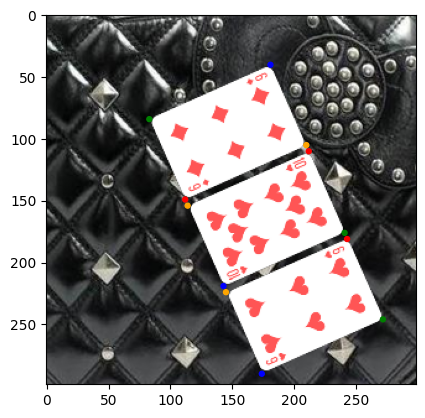

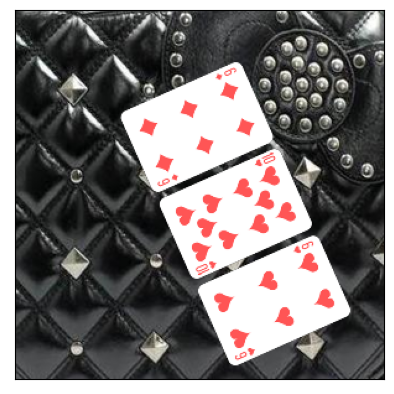

In [16]:
imageId = 0

images, labels, concepts, points, card_classes = next(iter(val_loader))
image, label = images[imageId], labels[imageId]

# print / show input
print("Image size (channels, width, height):", image.size())
print("Image concepts:", concepts[imageId])
print("Image class:", class_index_to_string(label.item()))

print("transformed image")


fig, ax = plt.subplots(1)
ax.imshow(np.asarray(images[imageId].squeeze().permute(1, 2, 0)))
for card in points[imageId]:
	for point_no in range(len(card)):
		if point_no == 0:
			ax.add_patch(Circle((card[point_no][0], card[point_no][1]), 2, color='red'))  # top left
		elif point_no == 1:
			ax.add_patch(Circle((card[point_no][0], card[point_no][1]), 2, color='green'))  # top right
		elif point_no == 2:
			ax.add_patch(Circle((card[point_no][0], card[point_no][1]), 2, color='orange'))  # bottom left
		else:
			ax.add_patch(Circle((card[point_no][0], card[point_no][1]), 2, color='blue'))  # bottom right
plt.show()    # Default is a blocking call


plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

# Multi image dataset

In [5]:
N_CONCEPT = 52
N_CLASSES = 6

val_loader = load_data("./dataset/individual_three_card_poker/train.pkl", 16, dataset_root="./dataset/individual_three_card_poker", return_orig=True, shuffle=True, multi_image=True)


card_class_index_to_string = IndexToString("./dataset/individual_three_card_poker/card_classes.txt")
card_concept_index_to_string = IndexToString("./dataset/individual_three_card_poker/card_concepts.txt")
hand_class_index_to_string = IndexToString("./dataset/individual_three_card_poker/hand_classes.txt")

TypeError: load_data() missing 1 required positional argument: 'num_concepts'

In [6]:
imageId = 0

images, labels, concepts, original_imgs = next(iter(val_loader))

# print / show input
print("Image size (channels, width, height):", images[imageId].size())
print("Image card classes:", concepts[imageId])
print("Hand rank class:", hand_class_index_to_string(labels[imageId].item()))

print("original image")

for image in images[imageId]:

    plt.xticks([])
    plt.yticks([])
    plt.imshow(image.squeeze().permute(1, 2, 0))
    plt.show()

print("transformed image")

for image in original_imgs[imageId]:

    plt.xticks([])
    plt.yticks([])
    plt.imshow(image.squeeze().permute(1, 2, 0))
    plt.show()

RuntimeError: Could not infer dtype of Image